# Notebook 07 — Tests de Robustesse & Ruptures Structurelles (2000–2025)

## Spécification Économétrique des Tests de Robustesse
1. **Modèle d'Interaction Capteur (Pente DMSP vs VIIRS)** :
   $$\ln(GDP_t) = \beta_0 + \beta_1 \ln(NTL_t) + \delta D_{\text{VIIRS}} + \theta (D_{\text{VIIRS}} \times \ln(NTL_t)) + \varepsilon_t$$
2. **Sensibilité à l'Anomalie 2017 (Échantillon Tronqué)** :
   * Estimation des modèles de croissance sur l'échantillon restreint excluant l'année 2017 ($N = 24$ diffs).
3. **Régressions par Sous-Échantillons de Capteurs** :
   * Sous-échantillon DMSP (2000–2011)
   * Sous-échantillon VIIRS (2012–2025)

In [1]:
# ==============================================================================
# 1. ESTIMATION DES MODÈLES DE ROBUSTESSE ET DE RUPTURE STRUCTURELLE
# ==============================================================================
from pathlib import Path
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# Configuration d'affichage
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.5f' % x)

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
tables_dir = project_root / "outputs" / "tables"
figures_dir = project_root / "outputs" / "figures"

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Chargement des données auditées
df = pd.read_csv(project_root / "data" / "intermediate" / "ntl_processed" / "niger_ntl_audited_2000_2025.csv")

# Variables Logarithmiques et Différences
df['ln_gdp'] = np.log(df['gdp_real'])
df['ln_ntl'] = np.log(df['ntl_sum_adj'])
df['d_ln_gdp'] = df['ln_gdp'].diff()
df['d_ln_ntl'] = df['ln_ntl'].diff()

# Terme d'interaction Capteur VIIRS * ln(NTL)
df['viirs_x_ln_ntl'] = df['dummy_viirs'] * df['ln_ntl']

# ------------------------------------------------------------------------------
# ESTIMATIONS OLS ROBUSTES (HAC)
# ------------------------------------------------------------------------------

# Robustesse 1 : Modèle d'interaction de pente (DMSP vs VIIRS)
m_inter = smf.ols('ln_gdp ~ ln_ntl + dummy_viirs + viirs_x_ln_ntl', data=df).fit(cov_type='HAC', cov_kwds={'maxlags': 2})

# Robustesse 2 : Croissance sur Échantillon Tronqué (Exclusion stricte de l'année 2017)
df_no2017 = df[df['year'] != 2017].dropna(subset=['d_ln_gdp', 'd_ln_ntl'])
m_no2017 = smf.ols('d_ln_gdp ~ d_ln_ntl', data=df_no2017).fit(cov_type='HAC', cov_kwds={'maxlags': 2})

# Robustesse 3a : Sous-échantillon DMSP/OLS (2000-2011)
df_dmsp = df[df['sensor'] == 'DMSP/OLS'].dropna(subset=['d_ln_gdp', 'd_ln_ntl'])
m_dmsp = smf.ols('d_ln_gdp ~ d_ln_ntl', data=df_dmsp).fit(cov_type='HAC', cov_kwds={'maxlags': 2})

# Robustesse 3b : Sous-échantillon VIIRS/DNB (2012-2025, hors 2017)
df_viirs_sub = df[(df['sensor'] == 'VIIRS') & (df['year'] != 2017)].dropna(subset=['d_ln_gdp', 'd_ln_ntl'])
m_viirs = smf.ols('d_ln_gdp ~ d_ln_ntl', data=df_viirs_sub).fit(cov_type='HAC', cov_kwds={'maxlags': 2})

print("[✓] Modèles de robustesse et de rupture structurelle estimés avec succès.")

[✓] Modèles de robustesse et de rupture structurelle estimés avec succès.


## Section 2 : Tableau Synthétique des Tests de Robustesse

Nous évaluons la sensibilité de nos estimations à trois niveaux :
1. **L'interaction de pente** : La relation en niveau a-t-elle changé de structure entre DMSP et VIIRS ?
2. **L'effet de l'anomalie 2017** : Quelle est la relation en croissance lorsque l'artefact satellitaire de 2017 est exclu ?
3. **La stabilité temporelle** : La relation est-elle plus forte au sein de chaque sous-période homogène (DMSP pur vs VIIRS pur) ?

In [2]:
# ==============================================================================
# 2. TABLEAU COMPARATIF DES MODÈLES DE ROBUSTESSE
# ==============================================================================

robustness_data = [
    {
        'Spécification': 'Modèle Interaction Capteur (Niveau)',
        'Échantillon': 'Complet (2000-2025)',
        'Coef NTL (β1)': m_inter.params.get('ln_ntl', np.nan),
        'p-val NTL': m_inter.pvalues.get('ln_ntl', np.nan),
        'Coef Interaction (VIIRS x NTL)': m_inter.params.get('viirs_x_ln_ntl', np.nan),
        'p-val Interaction': m_inter.pvalues.get('viirs_x_ln_ntl', np.nan),
        'R²': m_inter.rsquared,
        'Obs': int(m_inter.nobs)
    },
    {
        'Spécification': 'Croissance Hors 2017 (Tronqué)',
        'Échantillon': 'Hors Artefact 2017 (N=24)',
        'Coef NTL (β1)': m_no2017.params.get('d_ln_ntl', np.nan),
        'p-val NTL': m_no2017.pvalues.get('d_ln_ntl', np.nan),
        'Coef Interaction (VIIRS x NTL)': np.nan,
        'p-val Interaction': np.nan,
        'R²': m_no2017.rsquared,
        'Obs': int(m_no2017.nobs)
    },
    {
        'Spécification': 'Croissance DMSP Pur',
        'Échantillon': '2000-2011 (N=11 diffs)',
        'Coef NTL (β1)': m_dmsp.params.get('d_ln_ntl', np.nan),
        'p-val NTL': m_dmsp.pvalues.get('d_ln_ntl', np.nan),
        'Coef Interaction (VIIRS x NTL)': np.nan,
        'p-val Interaction': np.nan,
        'R²': m_dmsp.rsquared,
        'Obs': int(m_dmsp.nobs)
    },
    {
        'Spécification': 'Croissance VIIRS Pur (Hors 2017)',
        'Échantillon': '2012-2025 (N=12 diffs)',
        'Coef NTL (β1)': m_viirs.params.get('d_ln_ntl', np.nan),
        'p-val NTL': m_viirs.pvalues.get('d_ln_ntl', np.nan),
        'Coef Interaction (VIIRS x NTL)': np.nan,
        'p-val Interaction': np.nan,
        'R²': m_viirs.rsquared,
        'Obs': int(m_viirs.nobs)
    }
]

df_rob_summary = pd.DataFrame(robustness_data)

print("=======================================================================================")
print(" SUMMARY DES TESTS DE ROBUSTESSE ET DE RUPTURE STRUCTURELLE")
print("=======================================================================================")
print(df_rob_summary[['Spécification', 'Échantillon', 'Coef NTL (β1)', 'p-val NTL', 'R²', 'Obs']])

# Exportation CSV
tables_dir = project_root / "outputs" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)
out_rob_path = tables_dir / "07_robustness_summary.csv"
df_rob_summary.to_csv(out_rob_path, index=False)

print(f"\n[✓] Tableau récapitulatif de robustesse exporté vers : {out_rob_path}")

 SUMMARY DES TESTS DE ROBUSTESSE ET DE RUPTURE STRUCTURELLE
                         Spécification                Échantillon  \
0  Modèle Interaction Capteur (Niveau)        Complet (2000-2025)   
1       Croissance Hors 2017 (Tronqué)  Hors Artefact 2017 (N=24)   
2                  Croissance DMSP Pur     2000-2011 (N=11 diffs)   
3     Croissance VIIRS Pur (Hors 2017)     2012-2025 (N=12 diffs)   

   Coef NTL (β1)  p-val NTL      R²  Obs  
0        0.44491    0.00000 0.91628   26  
1        0.00326    0.70806 0.00145   24  
2        0.03838    0.14051 0.08983   11  
3       -0.00175    0.85564 0.00063   13  

[✓] Tableau récapitulatif de robustesse exporté vers : c:\Niger & Big Data\NTL et PIB Niger\niger_ntl_gdp\outputs\tables\07_robustness_summary.csv


[✓] Graphique des sous-échantillons sauvegardé dans : c:\Niger & Big Data\NTL et PIB Niger\niger_ntl_gdp\outputs\figures\07_robustness_subsamples_slopes.png


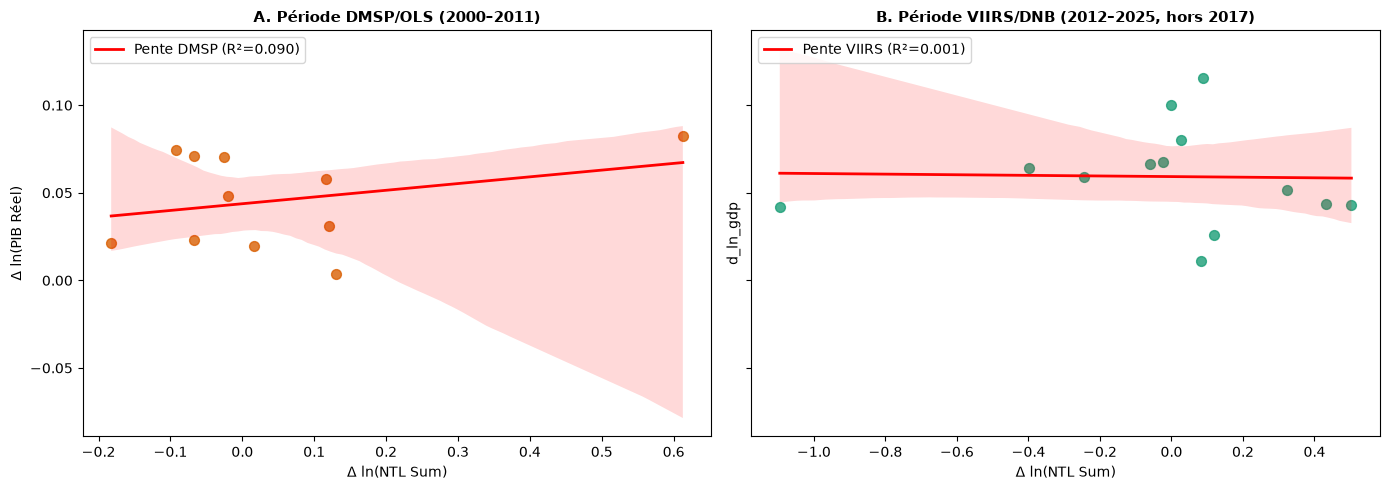

In [3]:
# ==============================================================================
# 3. VISUALISATION : PENTES DE RÉGRESSION DMSP VS VIIRS (CROISSANCE)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Graphique 1 : Période DMSP (2000-2011)
sns.regplot(
    data=df_dmsp, x='d_ln_ntl', y='d_ln_gdp', ax=ax1,
    scatter_kws={'color': '#d95f02', 's': 50, 'alpha': 0.8},
    line_kws={'color': 'red', 'linewidth': 2, 'label': f'Pente DMSP (R²={m_dmsp.rsquared:.3f})'}
)
ax1.set_title('A. Période DMSP/OLS (2000–2011)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Δ ln(NTL Sum)', fontsize=10)
ax1.set_ylabel('Δ ln(PIB Réel)', fontsize=10)
ax1.legend(loc='upper left')

# Graphique 2 : Période VIIRS (2012-2025, hors 2017)
sns.regplot(
    data=df_viirs_sub, x='d_ln_ntl', y='d_ln_gdp', ax=ax2,
    scatter_kws={'color': '#1b9e77', 's': 50, 'alpha': 0.8},
    line_kws={'color': 'red', 'linewidth': 2, 'label': f'Pente VIIRS (R²={m_viirs.rsquared:.3f})'}
)
ax2.set_title('B. Période VIIRS/DNB (2012–2025, hors 2017)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Δ ln(NTL Sum)', fontsize=10)
ax2.legend(loc='upper left')

plt.tight_layout()

# SAUVEGARDE DE LA FIGURE
figures_dir = project_root / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
fig_rob_png = figures_dir / "07_robustness_subsamples_slopes.png"
fig_rob_pdf = figures_dir / "07_robustness_subsamples_slopes.pdf"

plt.savefig(fig_rob_png, dpi=300, bbox_inches='tight')
plt.savefig(fig_rob_pdf, bbox_inches='tight')

print(f"[✓] Graphique des sous-échantillons sauvegardé dans : {fig_rob_png}")
plt.show()